# Class-label definitions

The dataset uses the following encodings:

- **Gallstone Status:** `0 = Yes`, `1 = No` (target variable)
- **Gender:** `0 = Male`, `1 = Female`
- **Comorbidity:** `0 = No comorbidities present`, `1 = One comorbid condition`, `2 = Two comorbid conditions`, `3 = Three or more comorbid conditions`
- **Coronary Artery Disease (CAD):** `0 = No`, `1 = Yes`
- **Hypothyroidism:** `0 = No`, `1 = Yes`
- **Hyperlipidemia:** `0 = No`, `1 = Yes`
- **Diabetes Mellitus (DM):** `0 = No`, `1 = Yes`
- **Hepatic Fat Accumulation (HFA):** `0 = No fat accumulation`, `1 = Grade 1 (mild)`, `2 = Grade 2 (moderate)`, `3 = Grade 3 (severe)`, `4 = Grade 4 (very severe)`

Because `Gallstone Status = 1` means **No gallstones**, evaluation metrics using the default positive class describe performance for the no-gallstone class.

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)


In [70]:
class DatasetLoader:
    """Load and prepare the Gallstone dataset."""

    def __init__(self, source):
        self.source = source

    def load(self):
        """Return the dataset as a pandas DataFrame."""
        print("Loading dataset from:", self.source)
        try:
            data = pd.read_csv(self.source, low_memory=False)
        except (OSError, ValueError) as error:
            print("Error loading dataset:", error)
            return pd.DataFrame()

        print("Dataset shape:", data.shape)
        return data

    def preprocess(self, data):
        """Apply dataset-specific cleaning before model training."""
        if data.empty:
            return data

        print("Preprocessing dataset...")
        processed = data.copy()
        string_columns = processed.select_dtypes(include="object").columns
        processed[string_columns] = processed[string_columns].apply(
            lambda column: column.str.lower()
        )
        return processed

    def run(self):
        return self.preprocess(self.load())


In [71]:
class DataProcessor:
    """Prepare features and target values for the model."""

    def __init__(self, data):
        self.data = data

    def process(self):
        """Return the processed data as a DataFrame."""
        print("Processing dataset...")
        return self.data.copy() if isinstance(self.data, pd.DataFrame) else pd.DataFrame(self.data)

    def split_features_and_target(self, target_column="Gallstone Status"):
        """Separate predictors from the target column."""
        if target_column not in self.data.columns:
            raise ValueError(f"Target column not found: {target_column}")

        features = self.data.drop(columns=[target_column])
        target = self.data[target_column]
        return features, target



In [72]:
class XGBoostModelTrainer:
    """Train and evaluate gallstone disease classification.

    Target encoding is kept unchanged:
        0 = Gallstones present
        1 = No gallstones

    Gallstone presence (class 0) is the clinical positive class for
    precision, sensitivity/recall, F1 and ROC-AUC.
    """

    def __init__(self, data):
        self.data = data

    def train(self):
        """Make one stratified hold-out split and fit an XGBClassifier."""
        processor = DataProcessor(self.data)
        features, target = processor.split_features_and_target()

        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(features, target,  test_size=0.2, random_state=42, stratify=target,)

        print(f"Training set shape: {self.X_train.shape}, " f"Test set shape: {self.X_test.shape}")

        model = xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42,)
        # xgboost suggested not to use the held-out test set as an evaluation/early-stopping set.
        model.fit(self.X_train, self.y_train)
        return model

    def evaluate(self, model):
        """Evaluate gallstones (class 0) as the positive clinical outcome."""
        predictions = model.predict(self.X_test)
        gallstone_index = list(model.classes_).index(0)
        gallstone_probabilities = model.predict_proba(self.X_test)[:, gallstone_index]
        gallstone_target = (self.y_test == 0).astype(int)

        metrics = {
            "accuracy": accuracy_score(self.y_test, predictions),
            "precision_gallstones": precision_score(
                self.y_test, predictions, pos_label=0, zero_division=0
            ),
            "sensitivity_gallstones": recall_score(
                self.y_test, predictions, pos_label=0, zero_division=0
            ),
            "specificity_gallstones": recall_score(
                self.y_test, predictions, pos_label=1, zero_division=0
            ),
            "f1_gallstones": f1_score(
                self.y_test, predictions, pos_label=0, zero_division=0
            ),
            "roc_auc_gallstones": roc_auc_score(
                gallstone_target, gallstone_probabilities
            ),
        }

        print("\nClassification report (0 = Gallstones, 1 = No gallstones):")
        print(classification_report(
            self.y_test,
            predictions,
            labels=[0, 1],
            target_names=["Gallstones", "No gallstones"],
            zero_division=0,
        ))
        print("\nConfusion matrix (rows = actual; columns = predicted; order = [0, 1]):")
        print(confusion_matrix(self.y_test, predictions, labels=[0, 1]))
        return metrics

    def predict(self, model, new_data):
        """Predict original labels and provide probabilities for both classes."""

        features = pd.DataFrame(new_data).copy()

        expected_columns = list(self.X_train.columns)

        missing = [column for column in expected_columns if column not in features.columns]

        unexpected = [column for column in features.columns if column not in expected_columns]

        if missing or unexpected:
            raise ValueError(
                f"Missing columns: {missing}; unexpected columns: {unexpected}"
            )

        features = features[expected_columns]

        probabilities = model.predict_proba(features)

        return {"predictions": model.predict(features),"probability_gallstones": probabilities[:, list(model.classes_).index(0)], "probability_no_gallstones": probabilities[:, list(model.classes_).index(1)],}

    def explain(self, model):
        """Explain changes in P(gallstones), rather than P(no gallstones)."""
        background = self.X_train.sample(n=min(100, len(self.X_train)), random_state=42)
        explainer = shap.TreeExplainer(model, data=background, model_output="probability", feature_perturbation="interventional",)
        
        # Binary XGBoost's probability explanation targets class 1 (no gallstones).
        no_gallstone_explanation = explainer(self.X_test)
        # P(class 0) = 1 - P(class 1), so invert contributions and baseline.
        return shap.Explanation(
            values=-no_gallstone_explanation.values,
            base_values=1 - no_gallstone_explanation.base_values,
            data=no_gallstone_explanation.data,
            feature_names=list(self.X_test.columns),
        )

    def run(self):
        """Fit, evaluate and explain the model; keep the same return signature."""
        model = self.train()
        metrics = self.evaluate(model)
        explanations = self.explain(model)
        return model, metrics, explanations


In [ ]:


class DataVisualizer:
    """
    Create exploratory and evaluation plots with readable layouts.
    Template from XGBoost and SHAP documentation, adapted for gallstone disease classification.
    """

    def __init__(self, data):
        """Initialize visualizer with a copy of the dataset."""
        self.data = (
            data.copy()
            if isinstance(data, pd.DataFrame)
            else pd.DataFrame(data)
        )

    def plot_target_distribution(self, target="Gallstone Status"):
        """Plot the number of records in each target class."""
        if target not in self.data.columns:
            raise ValueError(f"Target column not found: {target}")

        counts = self.data[target].value_counts().sort_index()

        if counts.empty:
            raise ValueError("Target column contains no valid values.")

        width = max(8, len(counts) * 1.2)

        figure, axis = plt.subplots(
            figsize=(width, 5),
            layout="constrained"
        )

        bars = axis.bar(
            counts.index.astype(str),
            counts.values,
            color="steelblue",
            edgecolor="black",
            alpha=0.85,
            width=0.6
        )

        axis.set_title(
            f"Distribution of {target}",
            fontsize=14,
            fontweight="bold",
            pad=15
        )
        axis.set_xlabel(target, fontsize=11, labelpad=10)
        axis.set_ylabel("Number of records", fontsize=11)

        axis.tick_params(axis="both", labelsize=10)

        if len(counts) > 5:
            plt.setp(
                axis.get_xticklabels(),
                rotation=30,
                ha="right"
            )

        axis.set_ylim(0, max(counts.values) * 1.15)

        for bar in bars:
            height = bar.get_height()
            axis.annotate(
                f"{int(height)}",
                xy=(
                    bar.get_x() + bar.get_width() / 2,
                    height
                ),
                xytext=(0, 4),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=10
            )

        axis.grid(
            axis="y",
            linestyle="--",
            alpha=0.3
        )
        axis.set_axisbelow(True)

        return figure

    def plot_feature_distribution(self, feature, bins=20):
        """Plot a numeric histogram or categorical bar chart."""
        if feature not in self.data.columns:
            raise ValueError(f"Feature column not found: {feature}")

        values = self.data[feature].dropna()

        if values.empty:
            raise ValueError(f"No valid values found for {feature}")

        if pd.api.types.is_numeric_dtype(values):
            figure, axis = plt.subplots(
                figsize=(10, 6),
                layout="constrained"
            )

            axis.hist(
                values,
                bins=bins,
                color="steelblue",
                edgecolor="black",
                alpha=0.8
            )

            axis.set_xlabel(
                feature,
                fontsize=11,
                labelpad=10
            )
            axis.set_ylabel(
                "Number of records",
                fontsize=11
            )

            axis.grid(
                axis="y",
                linestyle="--",
                alpha=0.3
            )

        else:
            counts = values.value_counts().head(20)

            height = max(5, len(counts) * 0.45)

            figure, axis = plt.subplots(
                figsize=(11, height),
                layout="constrained"
            )

            bars = axis.barh(
                counts.index.astype(str),
                counts.values,
                color="steelblue",
                edgecolor="black",
                alpha=0.85
            )

            axis.invert_yaxis()

            axis.set_xlabel(
                "Number of records",
                fontsize=11
            )
            axis.set_ylabel(
                feature,
                fontsize=11
            )

            axis.tick_params(
                axis="y",
                labelsize=9,
                pad=5
            )

            axis.set_xlim(
                0,
                max(counts.values) * 1.15
            )

            for bar in bars:
                width = bar.get_width()
                axis.annotate(
                    f"{int(width)}",
                    xy=(
                        width,
                        bar.get_y() + bar.get_height() / 2
                    ),
                    xytext=(4, 0),
                    textcoords="offset points",
                    ha="left",
                    va="center",
                    fontsize=9
                )

            axis.grid(
                axis="x",
                linestyle="--",
                alpha=0.3
            )

        axis.set_title(
            f"Distribution of {feature}",
            fontsize=14,
            fontweight="bold",
            pad=15
        )

        axis.tick_params(axis="x", labelsize=10)
        axis.set_axisbelow(True)

        return figure

    def plot_correlation_matrix(self):
        """Plot correlations between numeric features."""
        numeric_data = self.data.select_dtypes(
            include="number"
        )

        if numeric_data.empty:
            raise ValueError(
                "At least one numeric column is required."
            )

        correlations = numeric_data.corr()

        labels = correlations.columns.tolist()
        n_features = len(labels)

        # Automatically increase plot size for more features.
        figure_size = max(10, n_features * 0.6)

        figure, axis = plt.subplots(
            figsize=(figure_size, figure_size),
            layout="constrained"
        )

        image = axis.imshow(
            correlations,
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            interpolation="nearest",
            aspect="equal"
        )

        colorbar = figure.colorbar(
            image,
            ax=axis,
            shrink=0.8,
            pad=0.02
        )
        colorbar.set_label(
            "Correlation",
            fontsize=11
        )

        axis.set_xticks(np.arange(n_features))
        axis.set_yticks(np.arange(n_features))

        axis.set_xticklabels(
            labels,
            rotation=90,
            ha="center",
            fontsize=9
        )
        axis.set_yticklabels(
            labels,
            fontsize=9
        )

        axis.tick_params(
            axis="both",
            which="major",
            pad=6,
            length=0
        )

        axis.set_title(
            "Correlation Matrix",
            fontsize=15,
            fontweight="bold",
            pad=20
        )

        # Display correlation values when the matrix
        # is small enough to remain readable.
        if n_features <= 12:
            for row in range(n_features):
                for col in range(n_features):
                    value = correlations.iloc[row, col]

                    if np.isnan(value):
                        text = "N/A"
                        text_color = "black"
                    else:
                        text = f"{value:.2f}"
                        text_color = (
                            "white"
                            if abs(value) > 0.6
                            else "black"
                        )

                    axis.text(
                        col,
                        row,
                        text,
                        ha="center",
                        va="center",
                        fontsize=8,
                        color=text_color
                    )

        return figure

    def plot_confusion_matrix(self, actual, predicted):
        """Plot a confusion matrix from actual and predicted labels."""
        actual = np.asarray(actual).ravel()
        predicted = np.asarray(predicted).ravel()

        if (
            actual.shape != predicted.shape
            or actual.size == 0
        ):
            raise ValueError(
                "Actual and predicted values must "
                "be non-empty and aligned."
            )

        # Preserve the original target encoding.
        labels = [0, 1]

        matrix = confusion_matrix(
            actual,
            predicted,
            labels=labels
        )

        figure, axis = plt.subplots(
            figsize=(8, 6),
            layout="constrained"
        )

        image = axis.imshow(
            matrix,
            cmap="Blues",
            interpolation="nearest"
        )

        colorbar = figure.colorbar(
            image,
            ax=axis,
            shrink=0.8,
            pad=0.04
        )
        colorbar.set_label(
            "Number of predictions",
            fontsize=10
        )

        names = [
            "Gallstones (0)",
            "No gallstones (1)"
        ]

        axis.set_xticks([0, 1])
        axis.set_yticks([0, 1])

        axis.set_xticklabels(
            names,
            rotation=15,
            ha="right",
            fontsize=10
        )
        axis.set_yticklabels(
            names,
            fontsize=10
        )

        axis.set_xlabel(
            "Predicted label",
            fontsize=12,
            labelpad=12
        )
        axis.set_ylabel(
            "Actual label",
            fontsize=12,
            labelpad=12
        )

        axis.set_title(
            "Held-out Test Confusion Matrix",
            fontsize=14,
            fontweight="bold",
            pad=20
        )

        threshold = matrix.max() / 2

        for row in range(2):
            for col in range(2):
                axis.text(
                    col,
                    row,
                    f"{matrix[row, col]:d}",
                    ha="center",
                    va="center",
                    fontsize=14,
                    fontweight="bold",
                    color=(
                        "white"
                        if matrix[row, col] > threshold
                        else "black"
                    )
                )

        axis.set_xlim(-0.5, 1.5)
        axis.set_ylim(1.5, -0.5)

        return figure


In [74]:
dataset_loader = DatasetLoader("data/dataset-uci/dataset-uci.csv")
data = dataset_loader.run()
processed_data = DataProcessor(data).process()


def main():
    trainer = XGBoostModelTrainer(processed_data)
    model, metrics, explanations = trainer.run()
    print("Evaluation metrics (gallstone presence = positive class):", metrics)
    return trainer, model, metrics, explanations


# Keep the trained estimator and the held-out split available for later cells.
trainer, model, metrics, explanations = main()


Loading dataset from: data/dataset-uci/dataset-uci.csv
Dataset shape: (319, 39)
Preprocessing dataset...
Processing dataset...
Training set shape: (255, 38), Test set shape: (64, 38)

Classification report (0 = Gallstones, 1 = No gallstones):
               precision    recall  f1-score   support

   Gallstones       0.75      0.94      0.83        32
No gallstones       0.92      0.69      0.79        32

     accuracy                           0.81        64
    macro avg       0.83      0.81      0.81        64
 weighted avg       0.83      0.81      0.81        64


Confusion matrix (rows = actual; columns = predicted; order = [0, 1]):
[[30  2]
 [10 22]]
Evaluation metrics (gallstone presence = positive class): {'accuracy': 0.8125, 'precision_gallstones': 0.75, 'sensitivity_gallstones': 0.9375, 'specificity_gallstones': 0.6875, 'f1_gallstones': 0.8333333333333334, 'roc_auc_gallstones': 0.849609375}


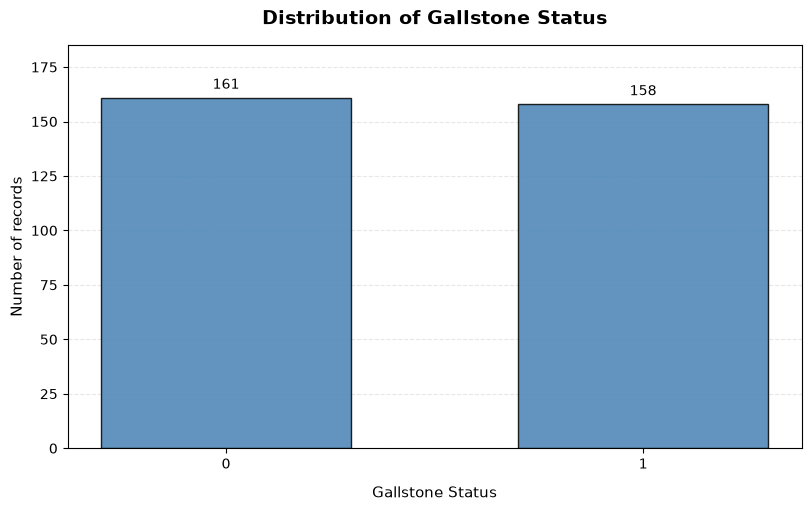

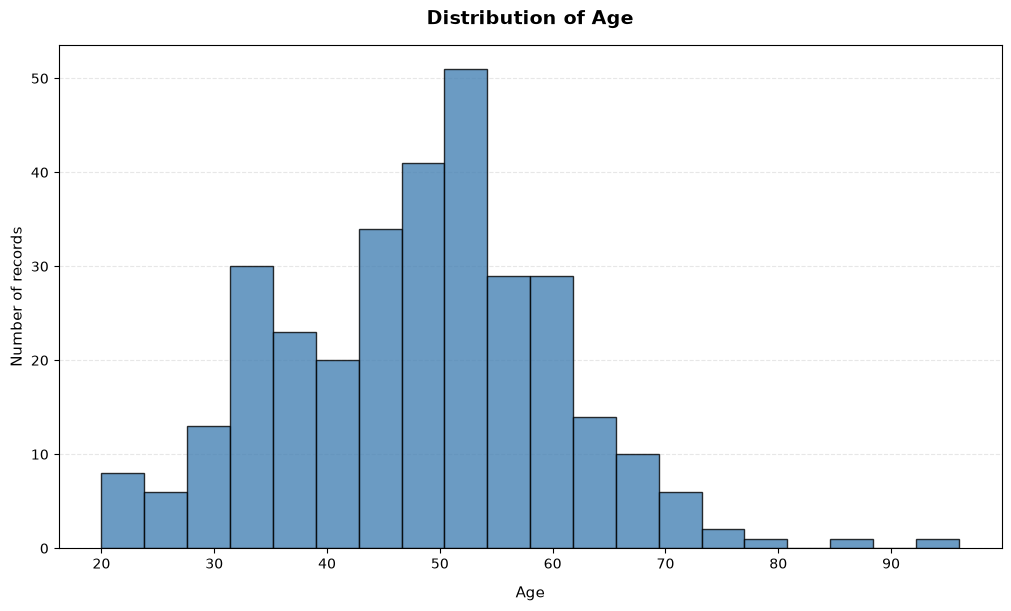

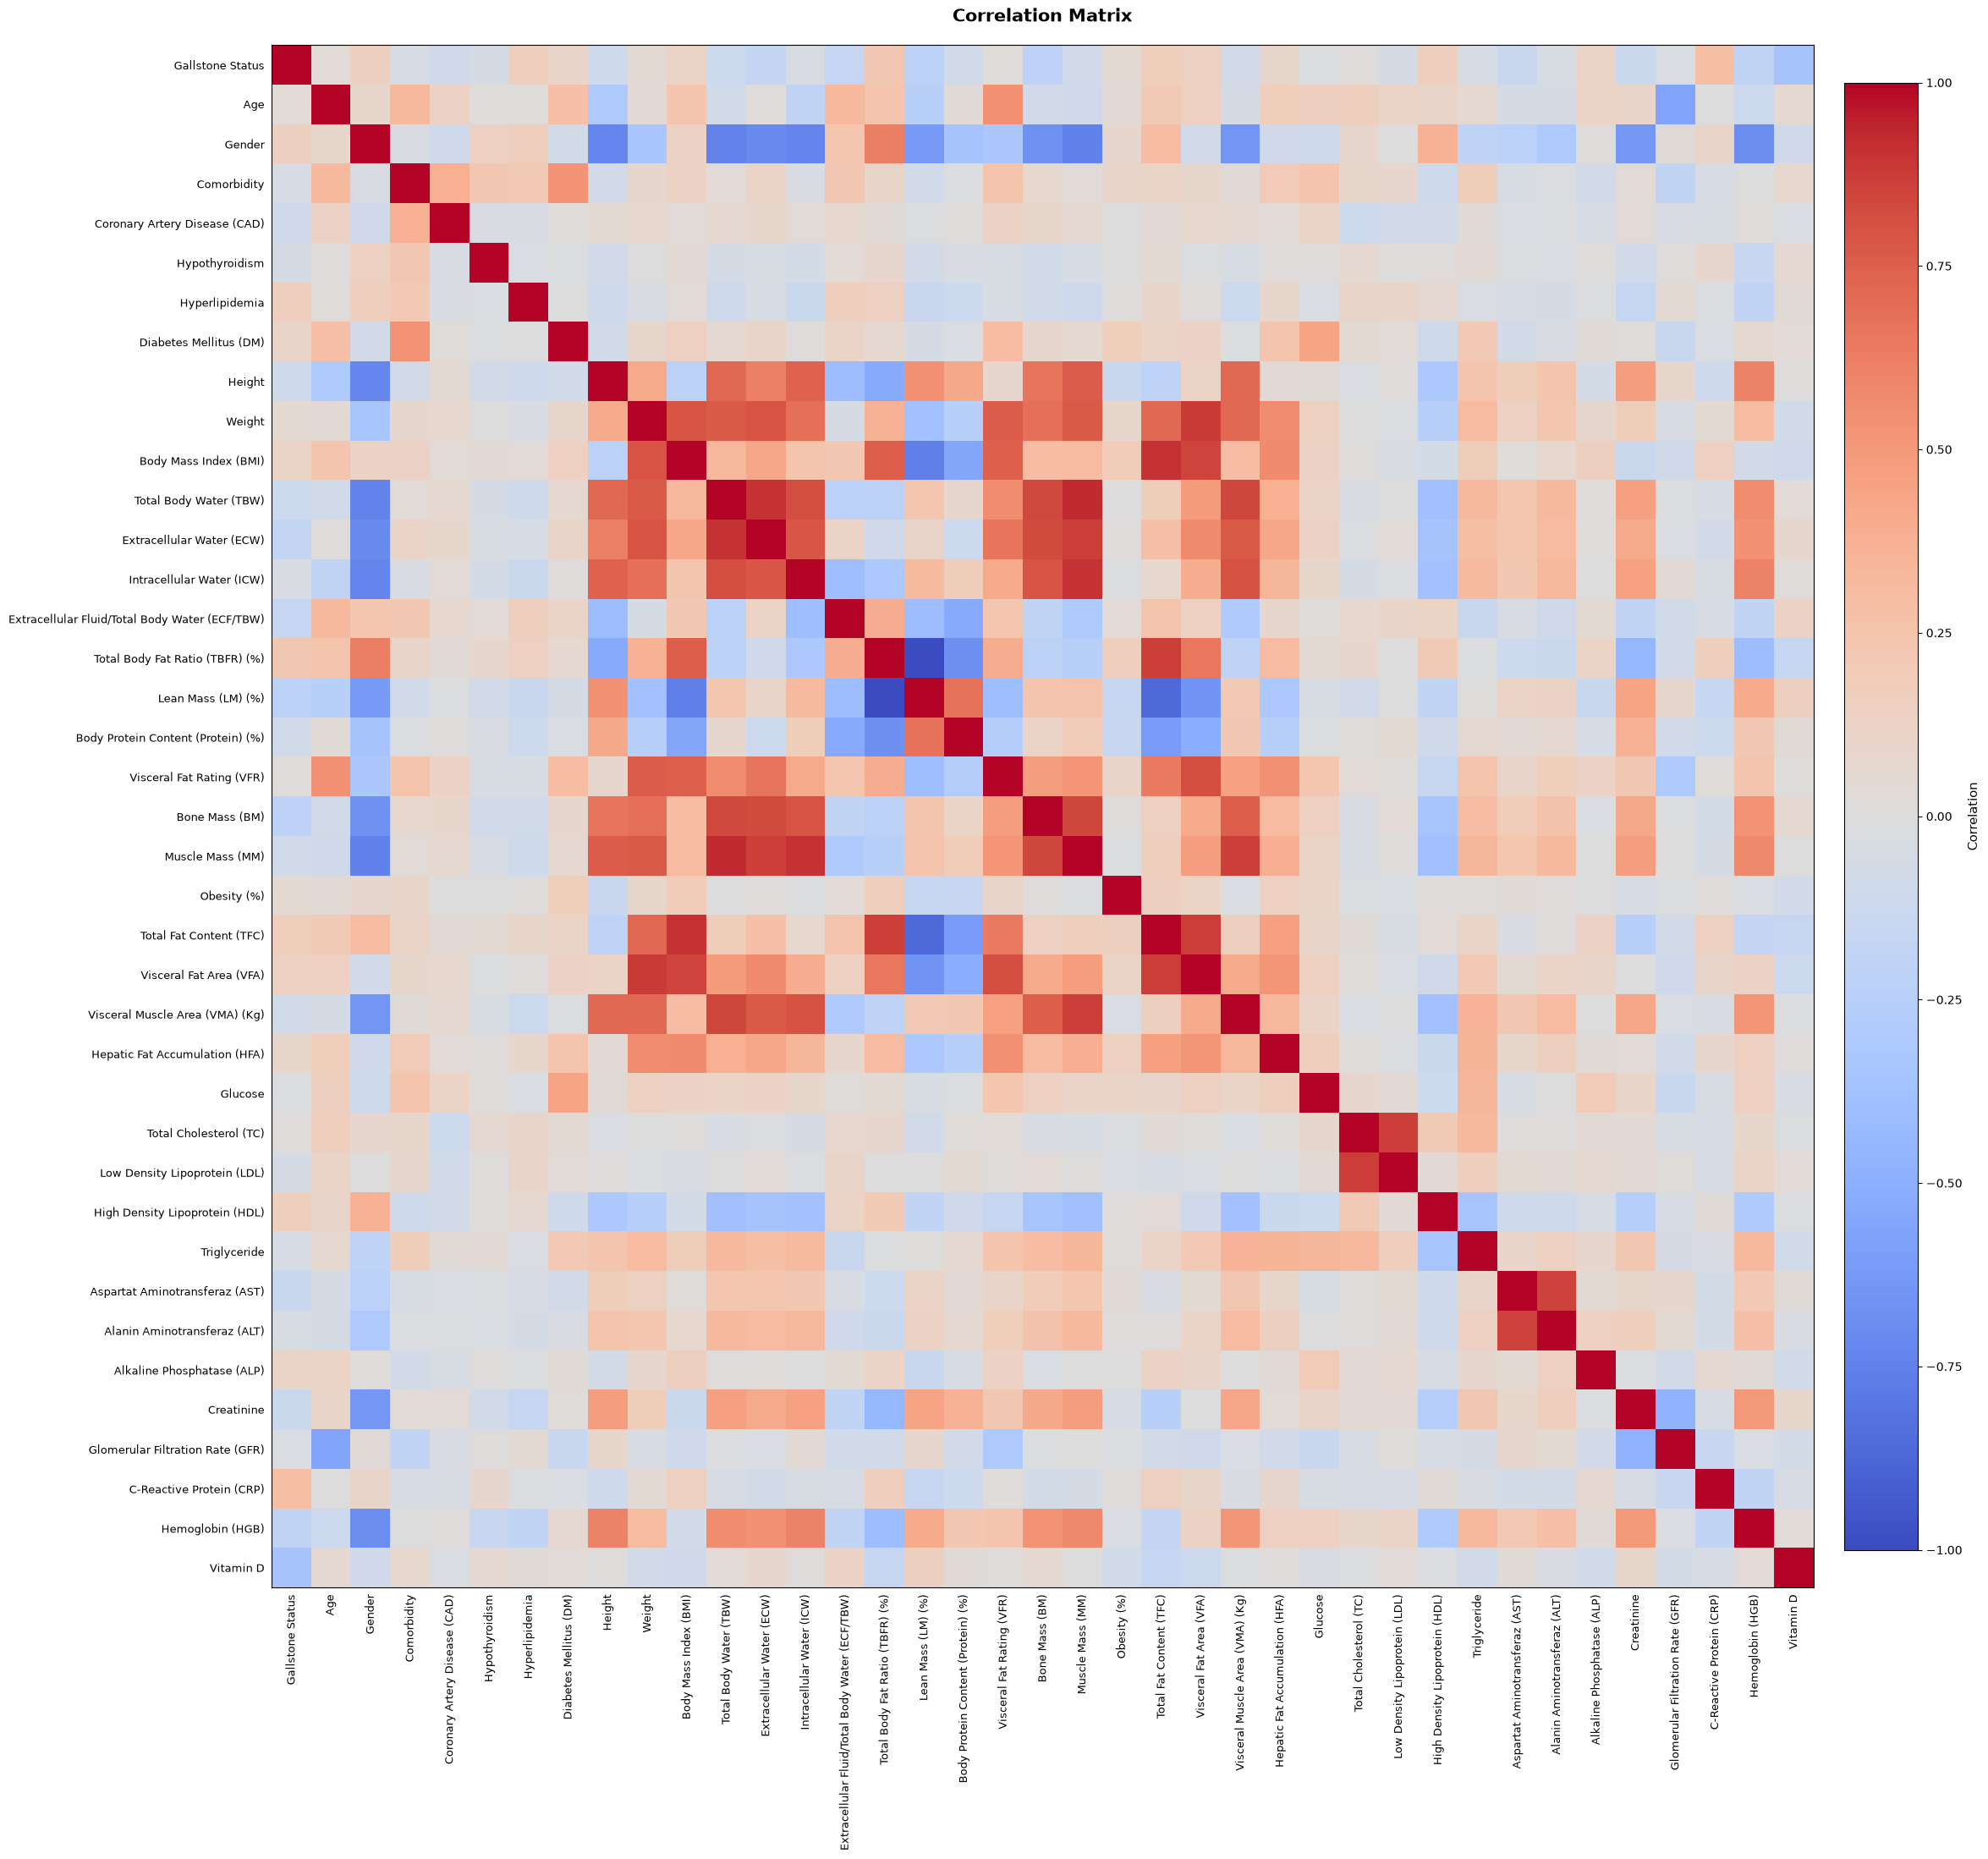

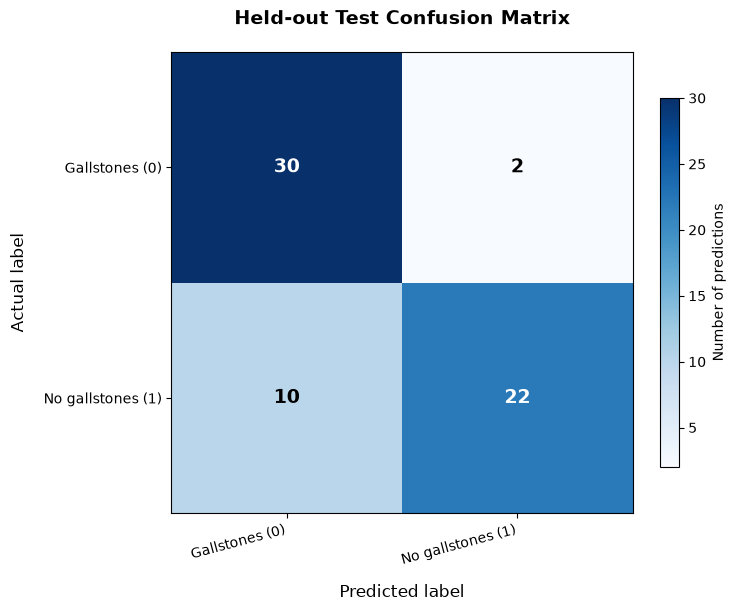

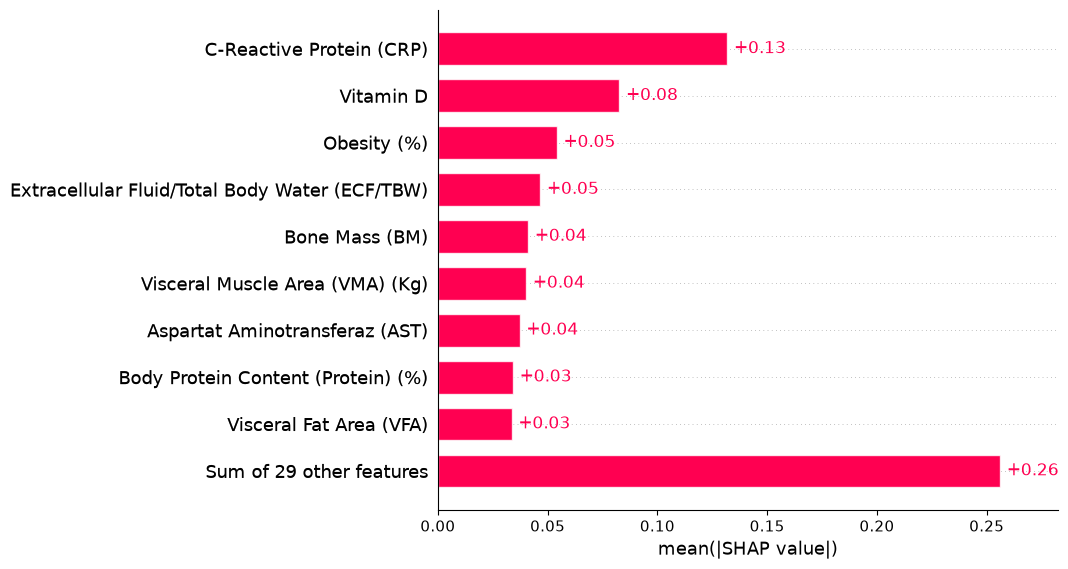

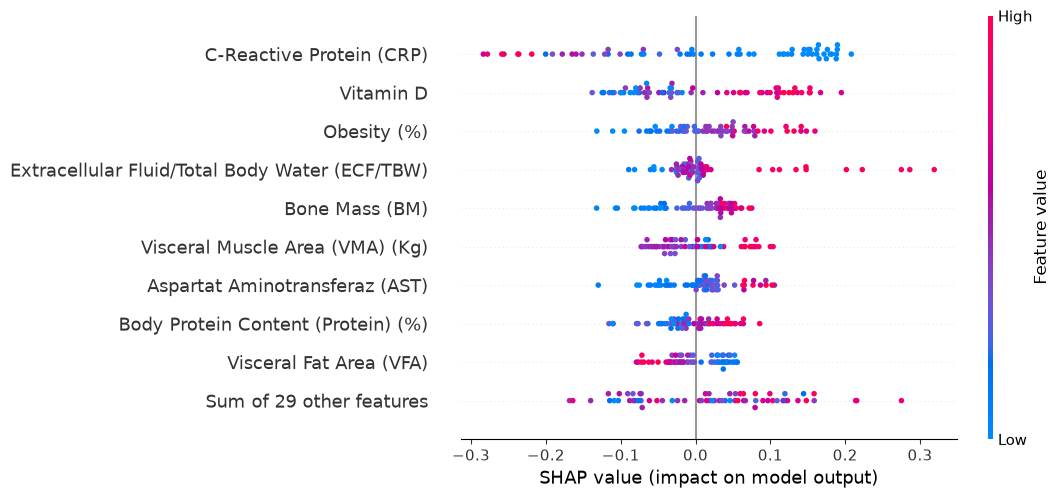

In [75]:
visualizer = DataVisualizer(data)
visualizer.plot_target_distribution(target="Gallstone Status")
plt.show()
visualizer.plot_feature_distribution(feature="Age")
plt.show()
visualizer.plot_correlation_matrix()
plt.show()

# Use actual held-out labels and predictions rather than manually entered examples.
test_predictions = model.predict(trainer.X_test)
visualizer.plot_confusion_matrix(actual=trainer.y_test, predicted=test_predictions)
plt.show()

# Positive SHAP values now increase P(gallstones = class 0).
shap.plots.bar(explanations, show=True)
plt.show()
shap.plots.beeswarm(explanations, show=True)
plt.show()
